In [1]:

%cd ..

from pathlib import Path
print(Path.cwd())

import numpy as np
import matplotlib.pyplot as plt

from hardware import ammeter, ammeter_uncertainty, gaussmeter, gaussmeter_uncertainty

plt.rcParams.update({
    "font.sans-serif": ["Cabin", "Libertinus Sans", "DejaVu Sans"],
    "font.serif": ["Libertinus Serif"],
    "font.family": "sans-serif",
    "font.style": "normal",
    "font.weight": "normal",
    "font.size": 14,
    "axes.labelsize": 16,
    "axes.titlesize": 18,
    "axes.titleweight": "bold",
    "axes.labelweight": "normal",
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 14,
    "legend.title_fontsize": 14,
    "figure.titlesize": 18,
    "figure.titleweight": "bold",
    "mathtext.fontset": "cm",
    "mathtext.default": "it",
    "axes.unicode_minus": False,
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.titlecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "legend.edgecolor": "black",
})
%matplotlib inline

from scipy.optimize import curve_fit

c:\Users\njwan\OneDrive - University of Toronto\Documents\Year 3\3F\PHY327\1 - Optical Pumping in Rubidium\code
c:\Users\njwan\OneDrive - University of Toronto\Documents\Year 3\3F\PHY327\1 - Optical Pumping in Rubidium\code


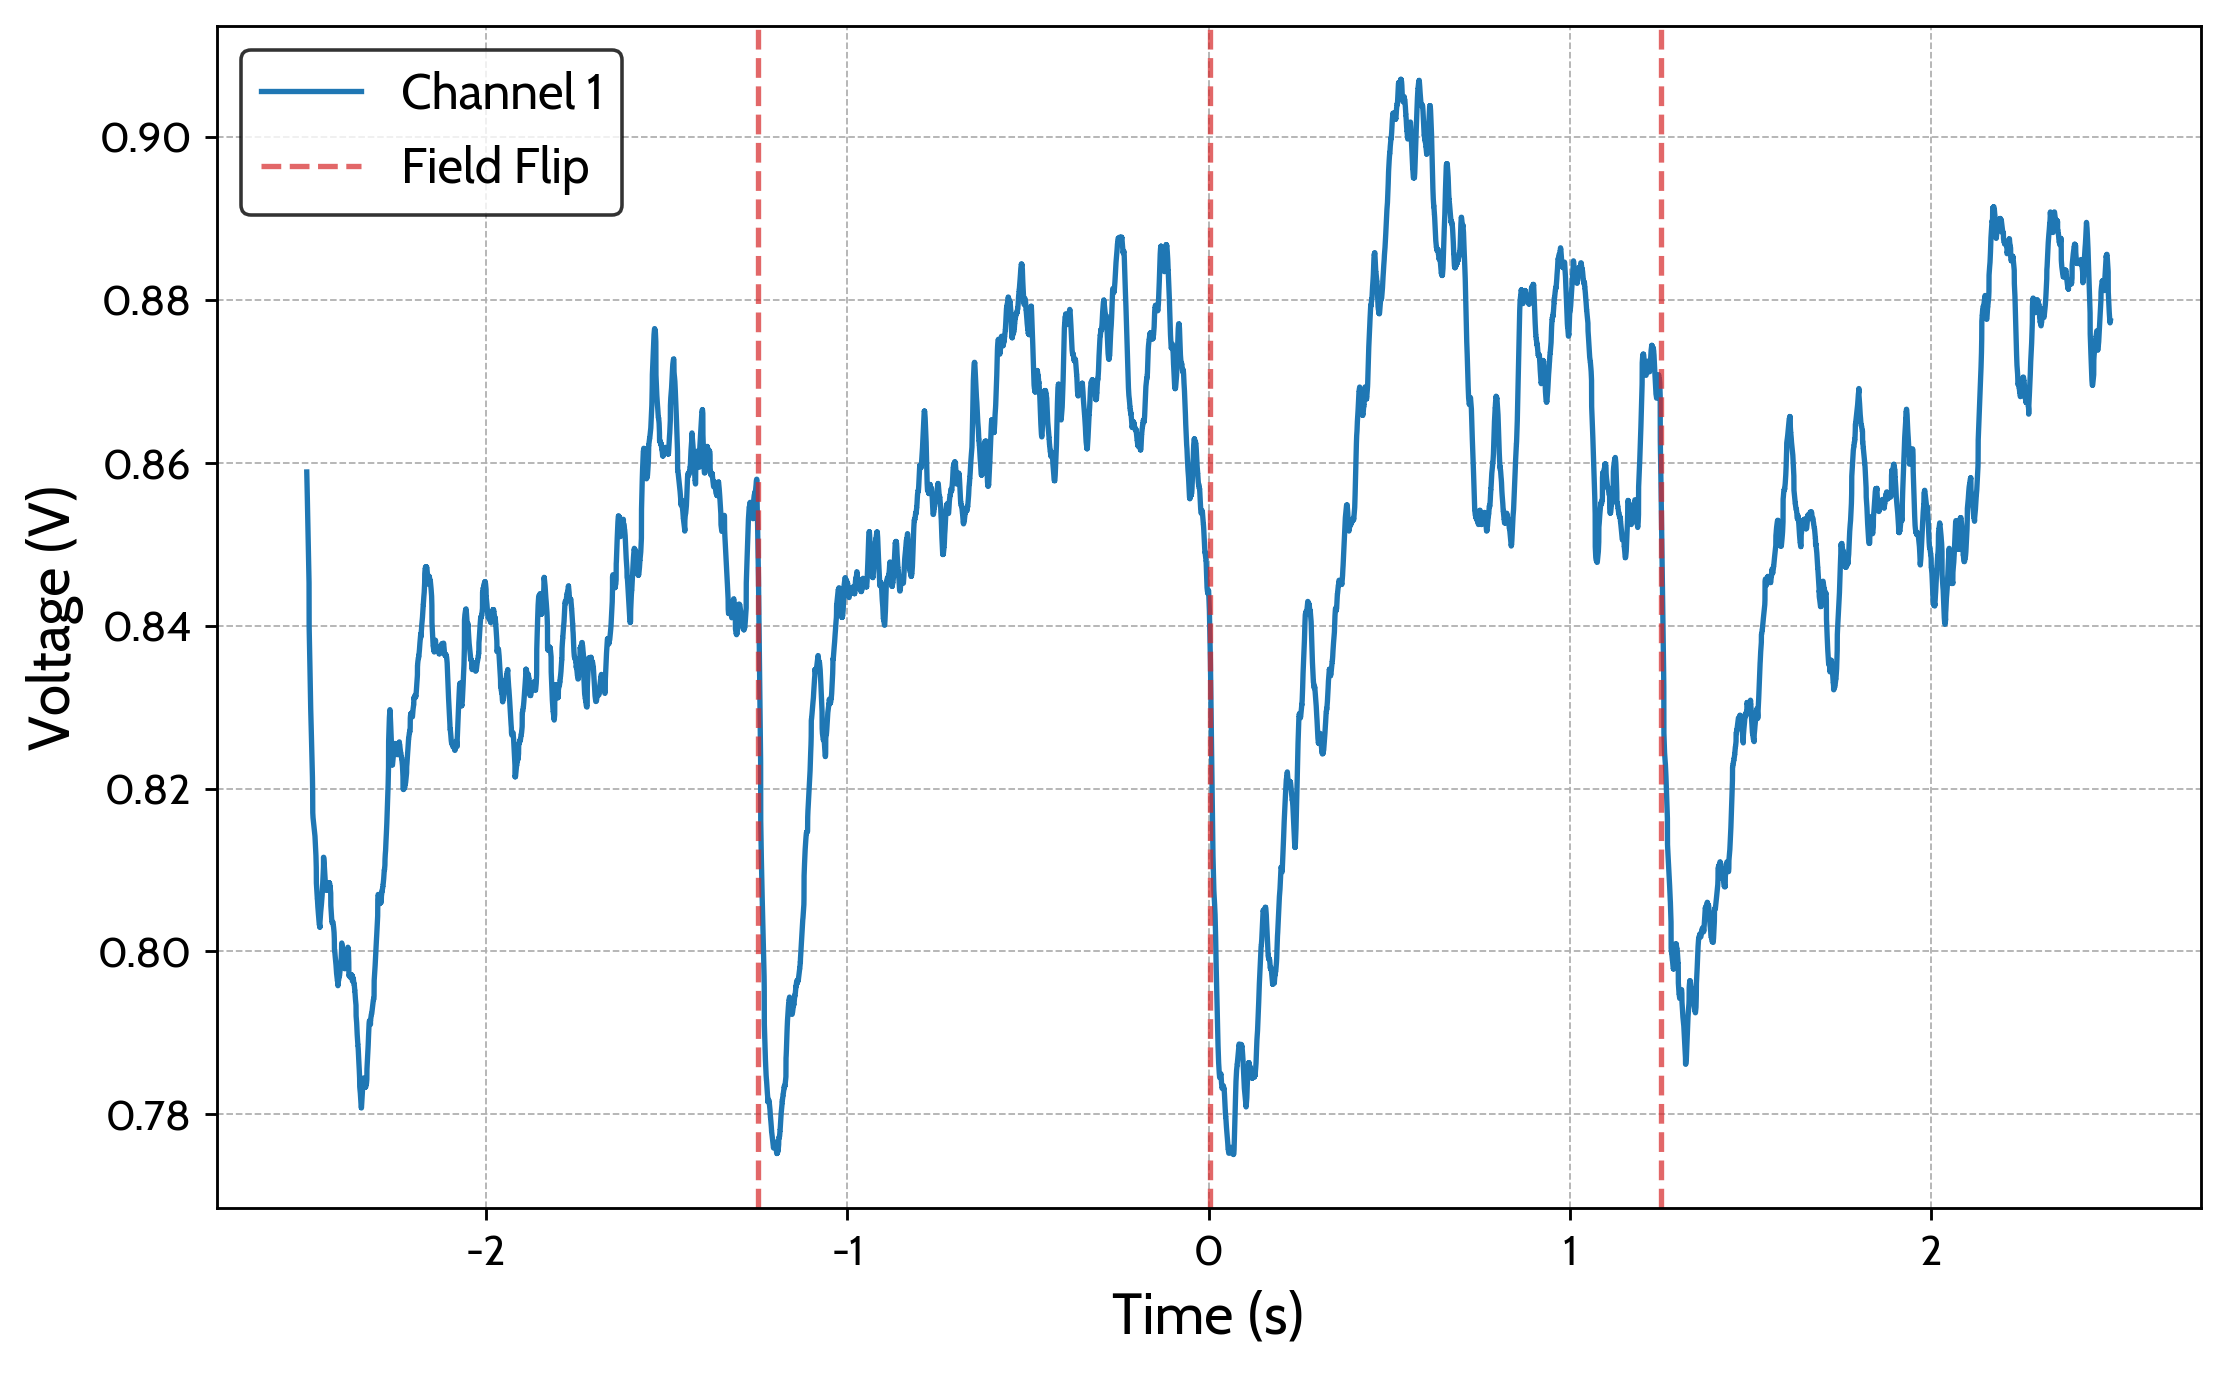

In [2]:
t, y1, y2 = np.loadtxt("analysis/scope_0.csv", delimiter=",", unpack=True, skiprows=1)

# finding the points where y2 crosses zero
zero_crossings = np.where(np.diff(np.sign(y2)))[0]

# averaging
n = 100  # number of points to average over
t = np.convolve(t, np.ones(n)/n, mode='valid')
y1 = np.convolve(y1, np.ones(n)/n, mode='valid')


fig, ax = plt.subplots(figsize=(10, 6), dpi = 256)
ax.plot(t, y1, label="Channel 1", linewidth=1.5)

for i in zero_crossings:
    if i == zero_crossings[0]:
        ax.axes.axvline(x=t[i], linestyle='--', linewidth=1.5, color = "tab:red", alpha = 0.7, label = "Field Flip")
    else:
     ax.axvline(x=t[i], linestyle='--', linewidth=1.5, color = "tab:red", alpha = 0.7)
    

ax.set_xlabel("Time (s)")
ax.set_ylabel("Voltage (V)")

ax.legend()

ax.grid(True, which='both', linestyle='--', linewidth=0.5)

[-0.30798192  0.50110494  0.66942353]
[0.0009051  0.00320218 0.00040335]


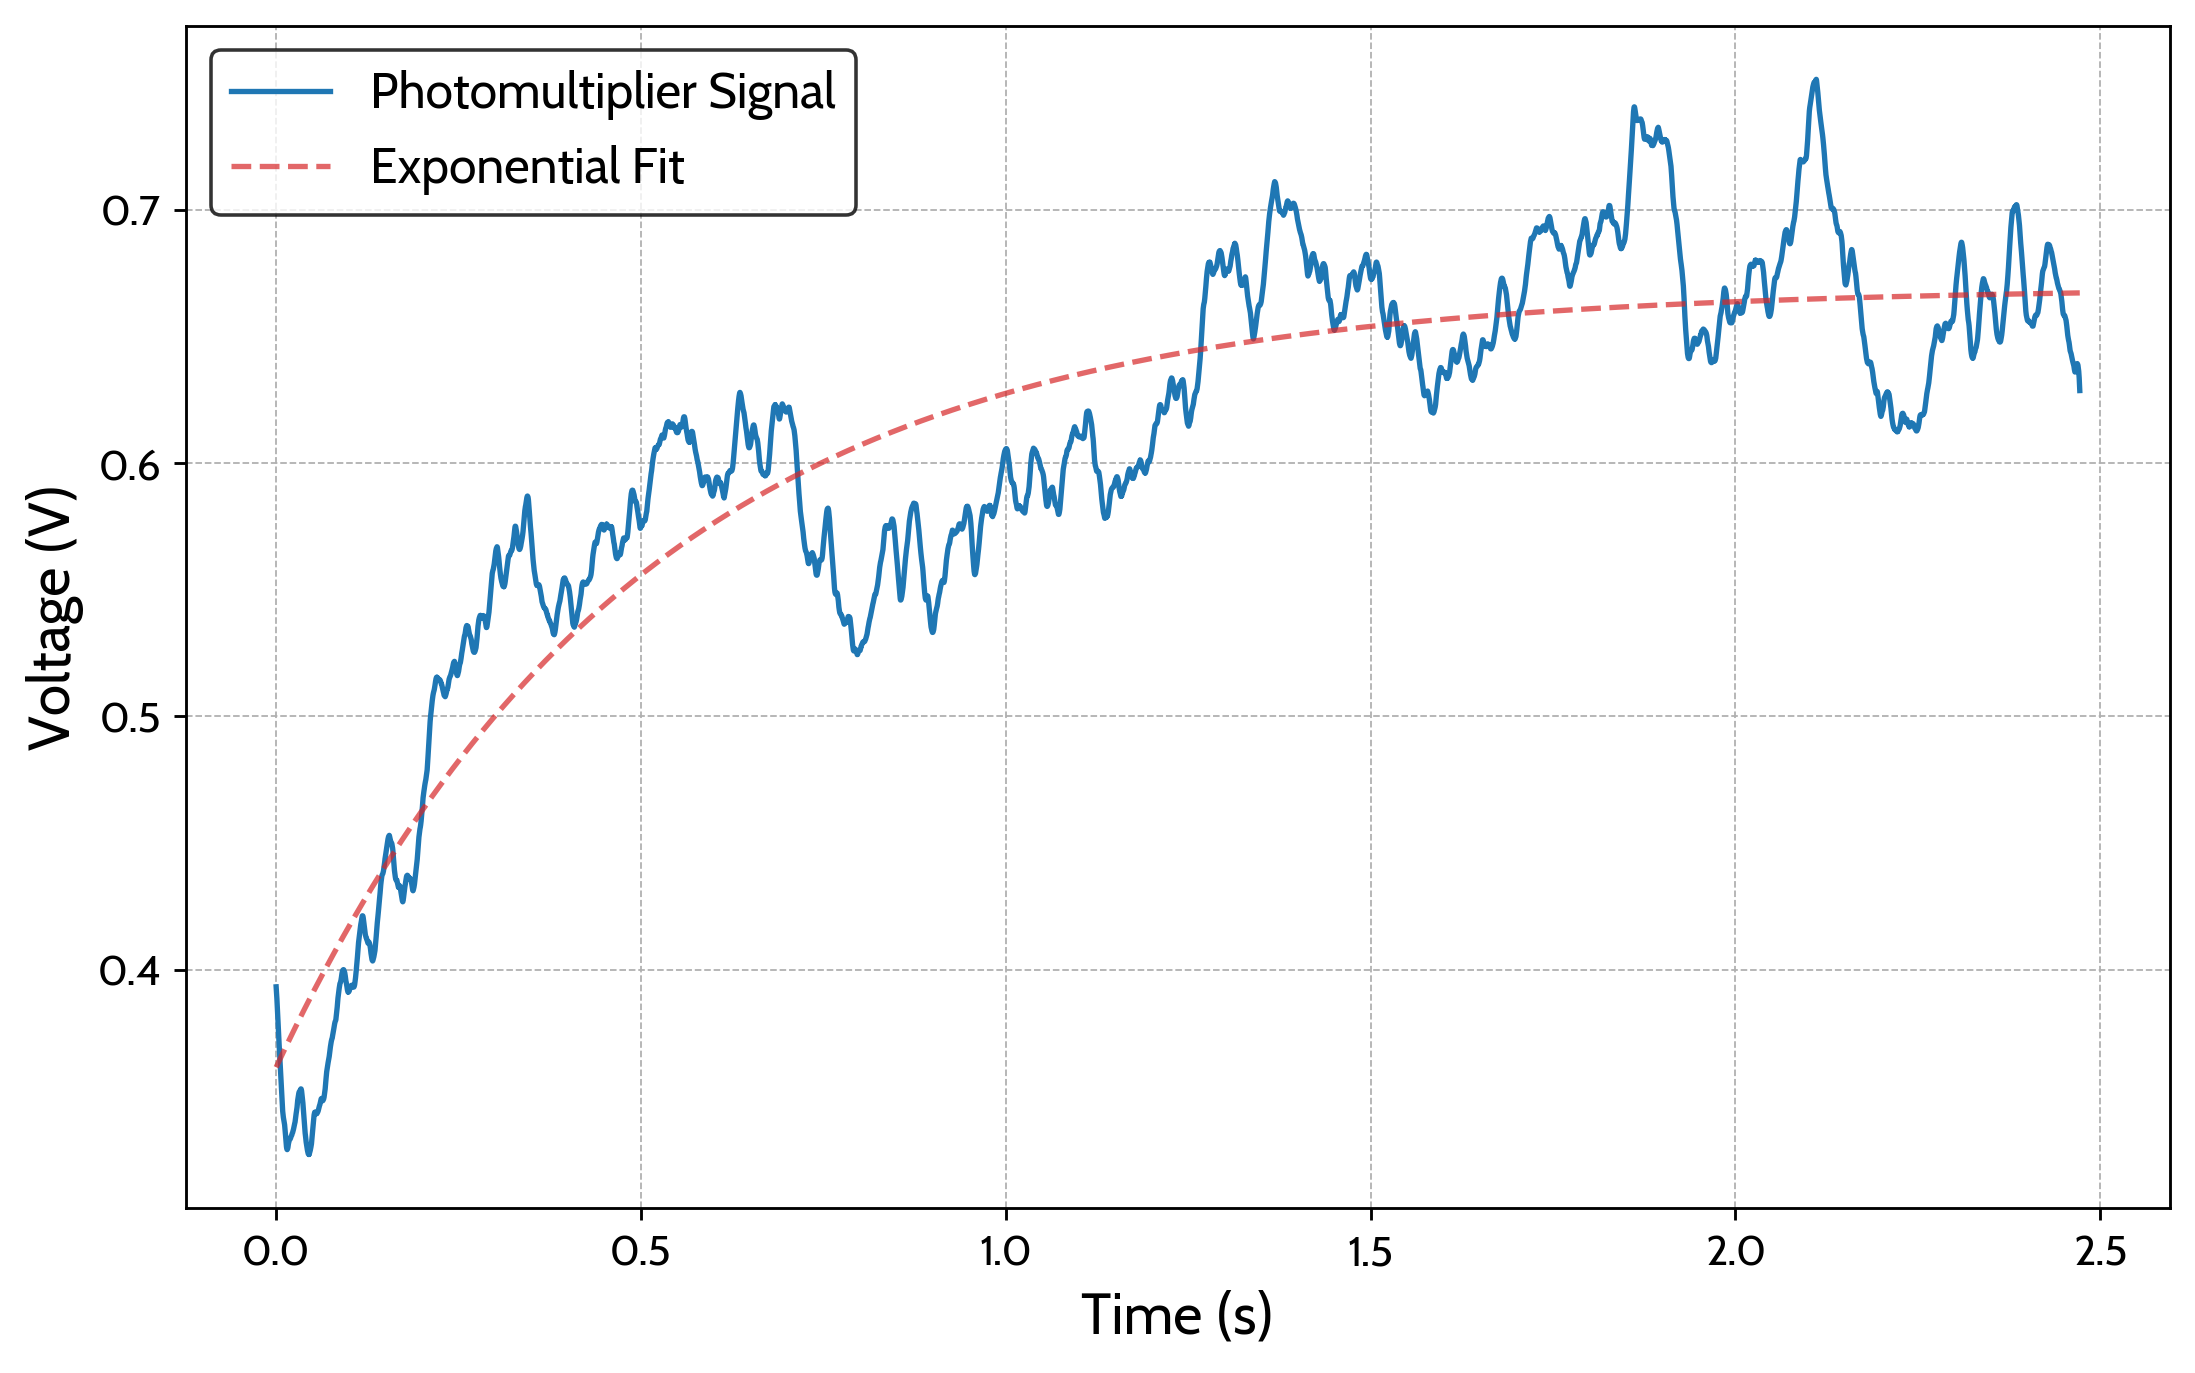

In [4]:
t, y1, y2 = np.loadtxt("analysis/scope_1.csv", delimiter=",", unpack=True, skiprows=2)

# finding the points where y2 crosses zero
zero_crossings = np.where(np.diff(np.sign(y2)))[0]

# averaging
n = 100  # number of points to average over
t = np.convolve(t, np.ones(n)/n, mode='valid')
y1 = np.convolve(y1, np.ones(n)/n, mode='valid')

# cut off data
y = y1[zero_crossings[0] + 350:zero_crossings[1]]
t = t[zero_crossings[0] + 350:zero_crossings[1]]
t = t - t[0]  

# fit: A is the initial amplitude above the asymptote,
# and tau is the 1/e decay time
def f(x, A, tau, c):
    return A * np.exp(-x / tau) + c

popt, pcov = curve_fit(f, t, y, p0=(0.2, 0.5, 0.7), maxfev=10000)

print(popt)
print(np.sqrt(np.diag(pcov)))

#plot

fig, ax = plt.subplots(figsize=(10, 6), dpi = 256)

ax.plot(t, y, label="Photomultiplier Signal", lw=1.5)
ax.plot(t, f(t, *popt), label="Exponential Fit", lw=1.5, color = "tab:red", alpha = 0.7, linestyle = "--")

ax.set_xlabel("Time (s)")
ax.set_ylabel("Voltage (V)")

ax.grid(True, which='both', linestyle='--', linewidth=0.5)

ax.legend()

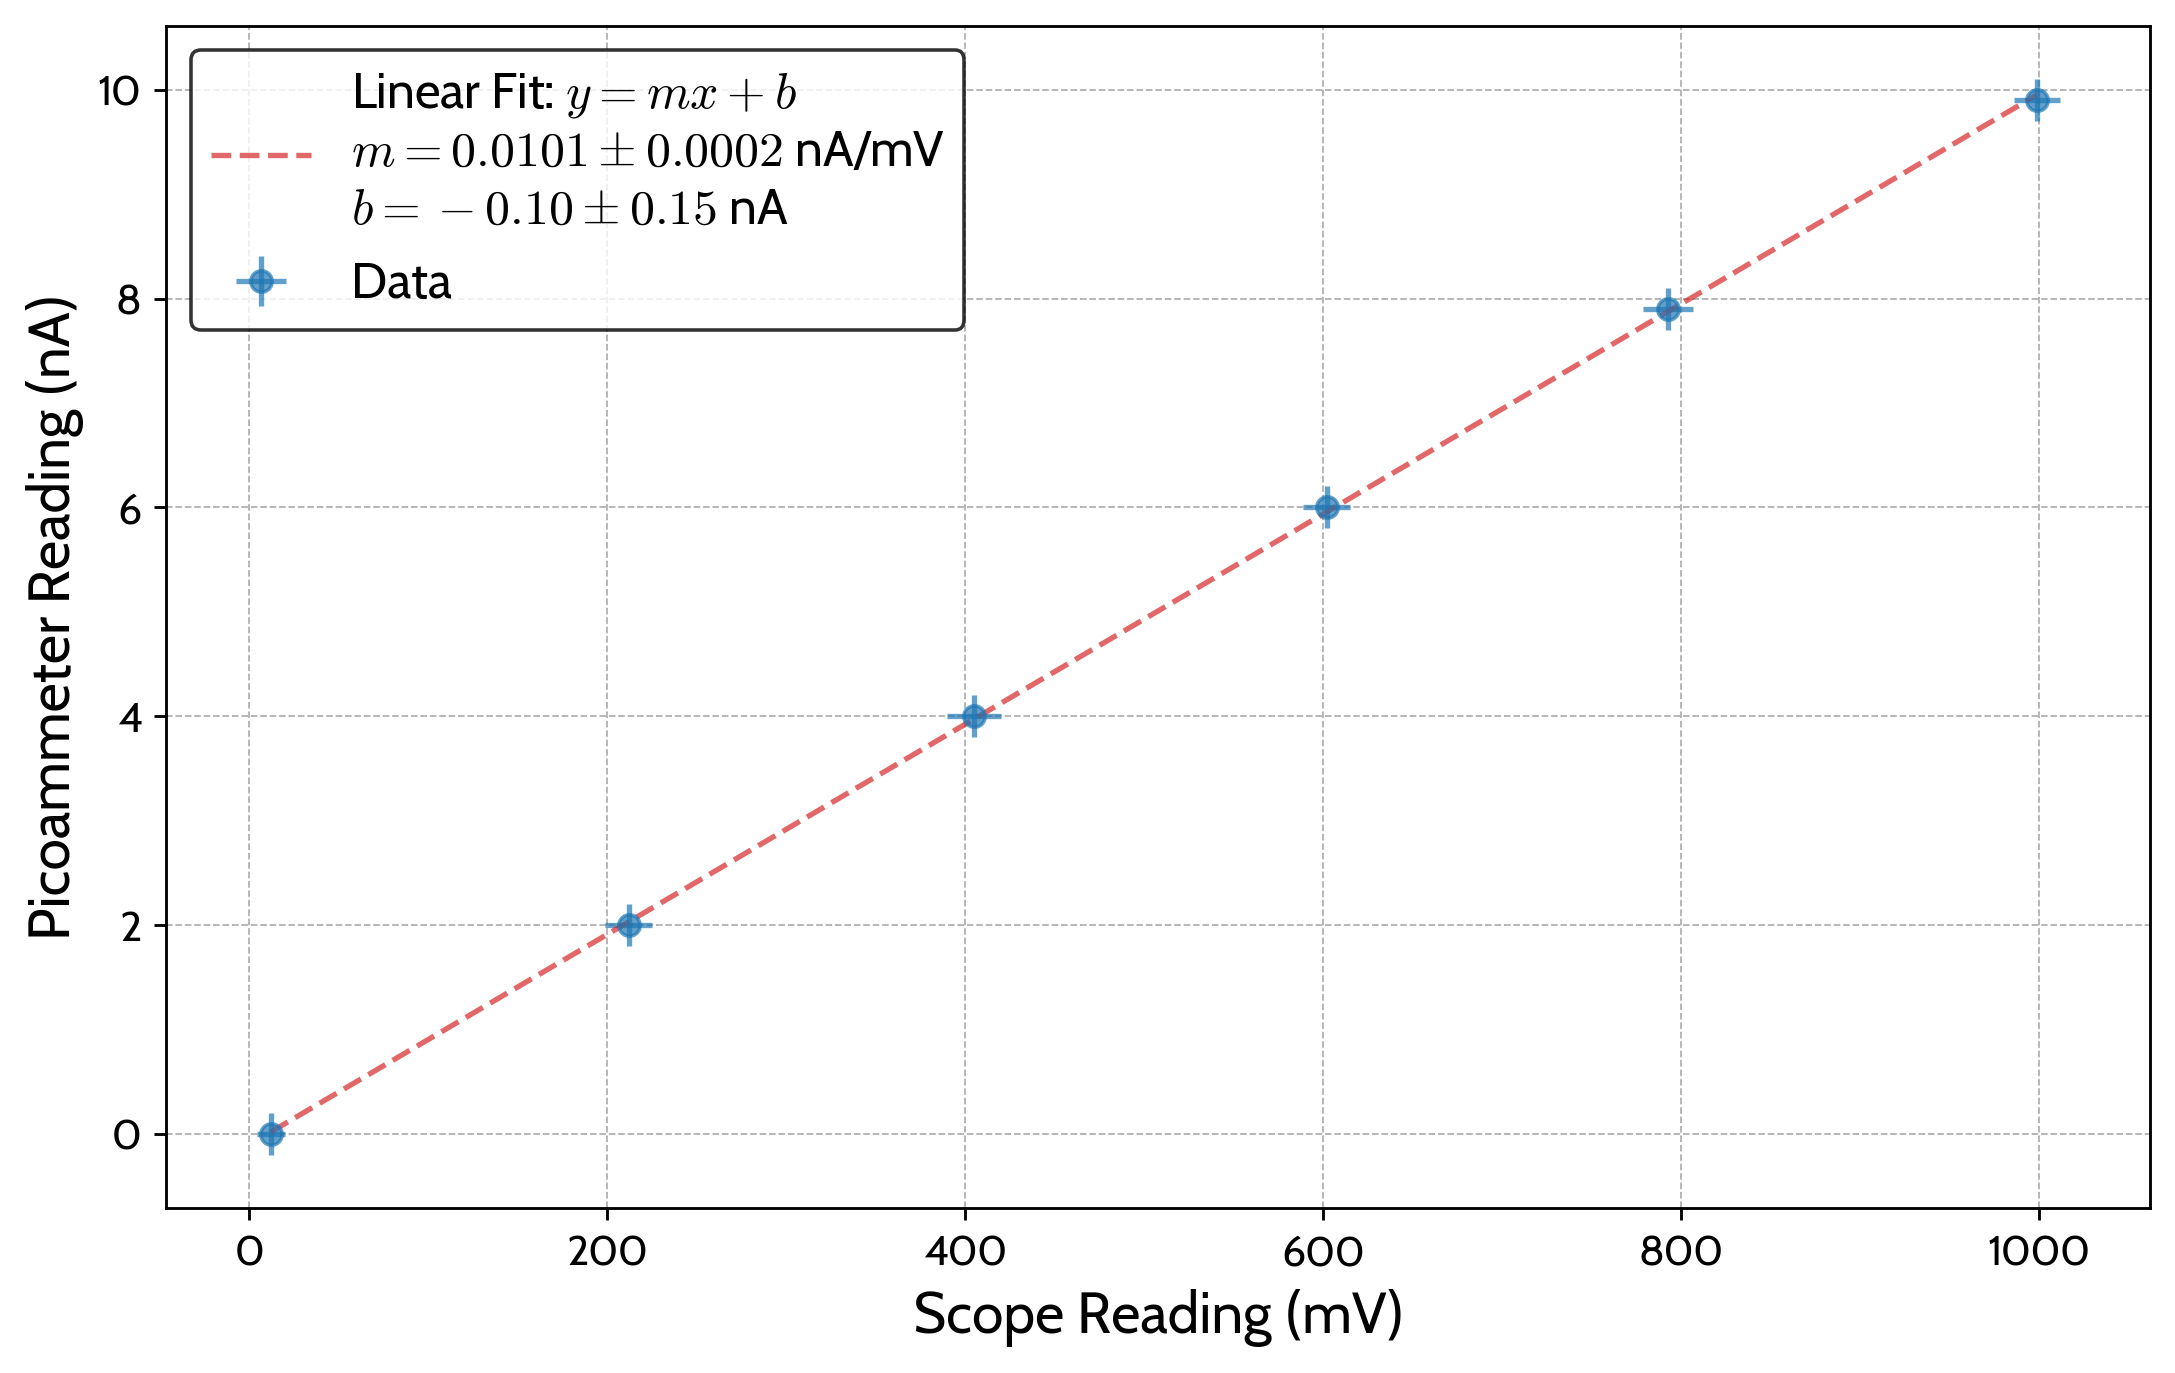

In [5]:
# picoammeter calibratino

A = np.array([0, 2, 4, 6, 7.9, 9.9])
Aerr = 0.2

Scope = np.array([12, 212, 405, 602, 793, 999])
Scopeerr = np.array([8, 13, 15, 13, 14, 13])

def f (x, a, b):
    return a * x + b

popt, pcov = curve_fit(f, Scope, A, sigma=Aerr*np.ones(len(A)), absolute_sigma=True)
label = f"Linear Fit: $y = mx + b$\n$m = {popt[0]:.4f} \pm {np.sqrt(np.diag(pcov))[0]:.4f}$ nA/mV\n$b = {popt[1]:.2f} \pm {np.sqrt(np.diag(pcov))[1]:.2f}$ nA"

fig, ax = plt.subplots(figsize=(10, 6), dpi = 256)
ax.errorbar(Scope, A, xerr=Scopeerr, yerr=Aerr, fmt='o', label="Data", color = "tab:blue", alpha = 0.7)
ax.plot(Scope, f(Scope, *popt), label= label, color = "tab:red", alpha = 0.7, linestyle = "--")

ax.set_xlabel("Scope Reading (mV)")
ax.set_ylabel("Picoammeter Reading (nA)")
ax.grid(True, which='both', linestyle='--', linewidth=0.5)
ax.legend()

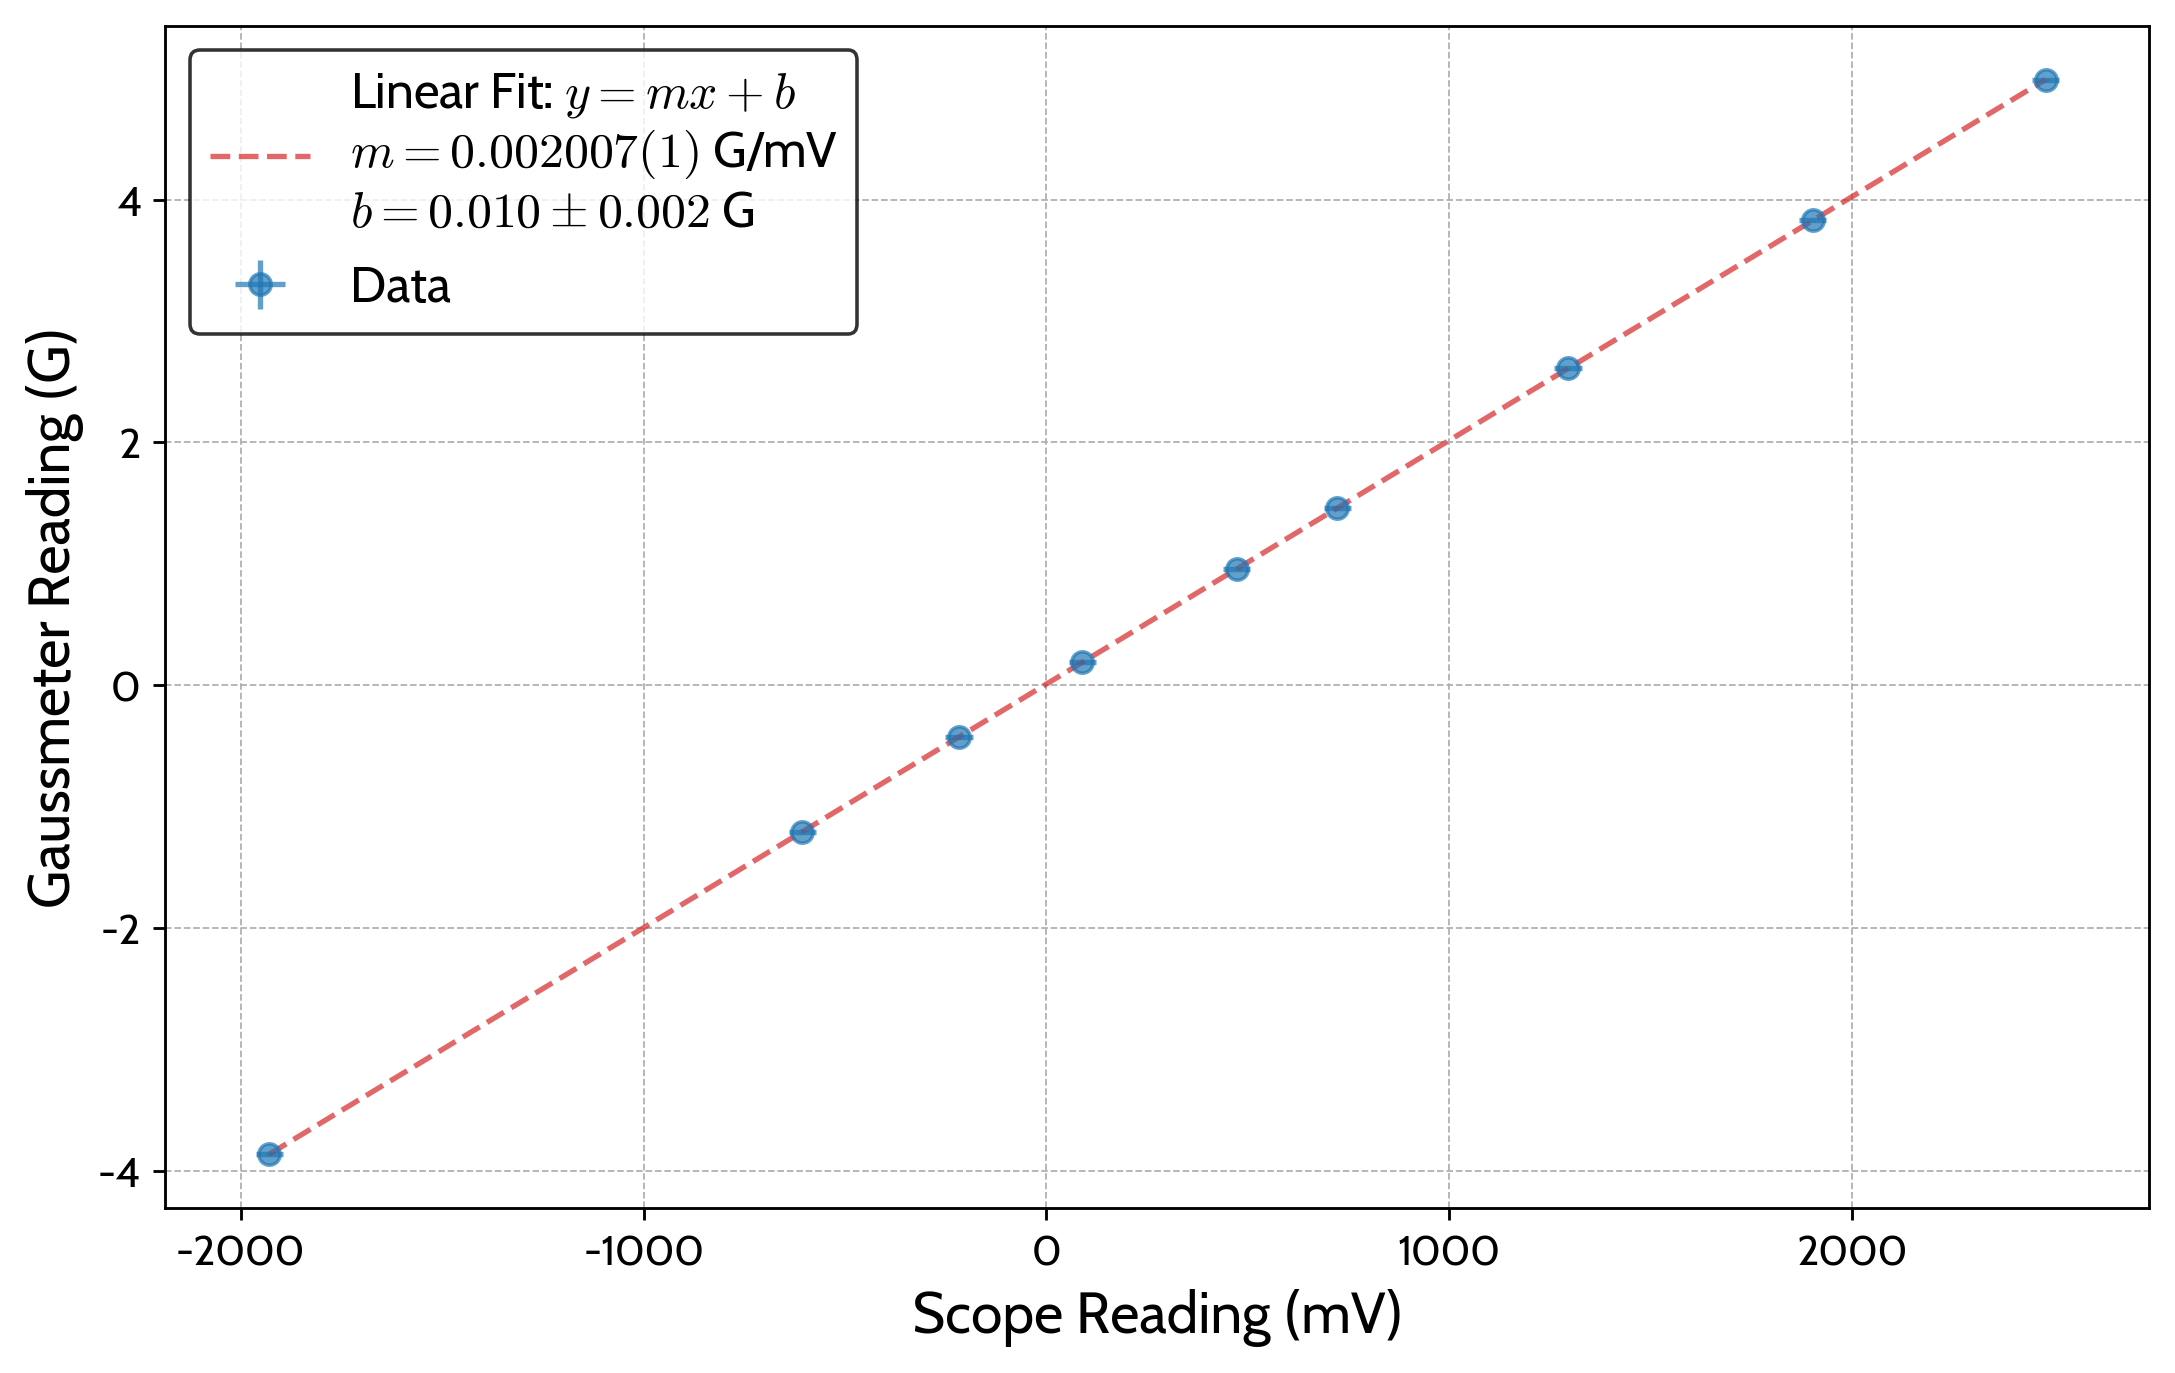

In [6]:
# gaussmeter calibration

G = np.array([-1.21, -.43, .191, .96, 1.462, 2.61, -3.86, 3.829, 4.985])
Gerr = 0.005

Scope = np.array([-606, -217, 89, 472, 722, 1295, -1929, 1902, 2480])
Scopeerr = 34

def f (x, a, b):
    return a * x + b

popt, pcov = curve_fit(f, Scope, G, sigma=np.ones(len(G))*Gerr, absolute_sigma=True)
label = f"Linear Fit: $y = mx + b$\n$m = {popt[0]:.6f}(1)$ G/mV\n$b = {popt[1]:.3f} \pm {np.sqrt(np.diag(pcov))[1]:.3f}$ G"

fig, ax = plt.subplots(figsize=(10, 6), dpi = 256)

ax.errorbar(Scope, G, xerr=Scopeerr, yerr=Gerr, fmt='o', label="Data", color = "tab:blue", alpha = 0.7)
ax.plot([Scope.min(), Scope[-1]], f(np.array([Scope.min(), Scope[-1]]), *popt), label= label, color = "tab:red", alpha = 0.7, linestyle = "--")

ax.set_xlabel("Scope Reading (mV)")
ax.set_ylabel("Gaussmeter Reading (G)")

ax.grid(True, which='both', linestyle='--', linewidth=0.5)
ax.legend()

In [9]:


gaussmeter(500), gaussmeter_uncertainty(500, 0)

(1.0135, 4.9999999999999996e-05)